# CIFAR-10 Image Classification: Benchmarking Architectures & Taming Transfer Learning

A systematic study evaluating inductive biases across four architectures: from a naive Fully Connected Baseline up to an optimized, two-stage fine-tuned ResNet-50 backbone on the CIFAR-10 dataset.

### Executive Performance Benchmark

| Model Strategy | Architectural Highlights | Key Bottleneck / Mechanism | Test Accuracy |
| :--- | :--- | :--- | :--- |
| **1. Fully Connected (MLP)** | Flatten + 3 Dense Layers | Loss of spatial hierarchies | ~48.0% |
| **2. Custom CNN** | 3x Conv blocks + MaxPooling + Dropout | Limited parameter capacity | ~65.2% |
| **3. ResNet-50 (Heavy Head)** | UpSampling + ResNet Base + Dense(128, 64) | Parameter explosion & heavy memory overhead | 93.42% |
| **4. ResNet-50 (Optimized Hero)**| 224x224 Resize + Augmentation + GAP + 2-Stage Tuning | Receptive field alignment + Anti-forgetting warm-up | **94.23%** |

In [ ]:
import py7zr

with py7zr.SevenZipFile('/content/cifar-10/train.7z', mode = 'r') as archive:
  archive.extractall(path = "/content/cifar-10/Training_Data")

In [ ]:
import pandas as pd
labels = pd.read_csv('/content/cifar-10/trainLabels.csv')
labels.head()

,id,label
0,1,frog
1,2,truck
2,3,truck
3,4,deer
4,5,automobile


In [ ]:
labels.shape

(50000, 2)

Label-Encoding the data

In [ ]:
labels['label'] = labels['label'].astype('category').cat.codes
labels.head()

,id,label
0,1,6
1,2,9
2,3,9
3,4,4
4,5,1


**Importing the data into a numpy array and saving it to drive**

In [ ]:
import numpy as np
images = np.zeros(shape = (50000, 32, 32, 3), dtype='uint8')

In [ ]:
from PIL import Image
train_data_path = '/content/cifar-10/Training_Data/train/'

for id in labels['id']:
  images[id-1] = np.array(Image.open(train_data_path + str(id) + '.png'))

array([[[ 59,  62,  63],
        [ 43,  46,  45],
        [ 50,  48,  43],
        ...,
        [158, 132, 108],
        [152, 125, 102],
        [148, 124, 103]],

       [[ 16,  20,  20],
        [  0,   0,   0],
        [ 18,   8,   0],
        ...,
        [123,  88,  55],
        [119,  83,  50],
        [122,  87,  57]],

       [[ 25,  24,  21],
        [ 16,   7,   0],
        [ 49,  27,   8],
        ...,
        [118,  84,  50],
        [120,  84,  50],
        [109,  73,  42]],

       ...,

       [[208, 170,  96],
        [201, 153,  34],
        [198, 161,  26],
        ...,
        [160, 133,  70],
        [ 56,  31,   7],
        [ 53,  34,  20]],

       [[180, 139,  96],
        [173, 123,  42],
        [186, 144,  30],
        ...,
        [184, 148,  94],
        [ 97,  62,  34],
        [ 83,  53,  34]],

       [[177, 144, 116],
        [168, 129,  94],
        [179, 142,  87],
        ...,
        [216, 184, 140],
        [151, 118,  84],
        [123,  92,  72]]], dtype=uint8)
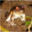

In [ ]:
images[0]

**Building the Neural Network**

In [1]:
import keras
from keras import layers
from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd
import cv2
from PIL import Image
import matplotlib.pyplot as plt

In [5]:
y_data = labels[:,1]
y_data

array([6, 9, 9, ..., 9, 1, 1])

Split the data to train and test

In [6]:
X_train, X_test, y_train, y_test = train_test_split(images, y_data, test_size = 0.2, random_state = 42)

In [ ]:
X_train.shape

(40000, 32, 32, 3)

Normalize X_train data

In [7]:
X_train_scaled = X_train.astype('float32') / 255.0
X_test_scaled = X_test.astype('float32') / 255.0

## Stage 1: Baseline Multi-Layer Perceptron (MLP)
We start with a naive fully-connected neural network to establish an empirical lower-bound. 
* **Hypothesis:** Flattening raw $(32 \times 32 \times 3)$ pixel matrices discards local 2D spatial correlations and translation invariance, forcing Dense layers to memorize spatial coordinates rather than structural patterns.

## Building a Normal NN using Keras

In [ ]:
Input_shape = (32,32,3)
class_size = 10
model = keras.Sequential([
    layers.Flatten(input_shape = Input_shape),
    layers.Dense(256, activation='relu'),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(class_size, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [ ]:
model.fit(X_train_scaled, y_train, epochs=20, validation_split=0.1)

Epoch 1/20
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.3025 - loss: 1.9227 - val_accuracy: 0.3720 - val_loss: 1.7528
Epoch 2/20
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.3748 - loss: 1.7356 - val_accuracy: 0.3910 - val_loss: 1.6944
Epoch 3/20
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.4037 - loss: 1.6584 - val_accuracy: 0.4038 - val_loss: 1.6752
Epoch 4/20
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.4218 - loss: 1.6141 - val_accuracy: 0.4170 - val_loss: 1.6440
Epoch 5/20
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.4386 - loss: 1.5687 - val_accuracy: 0.4288 - val_loss: 1.5850
Epoch 6/20
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.4578 - loss: 1.5224 - val_accuracy: 0.4322 - val_loss: 1.5837
Epoch 7/20
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.4642 - loss: 1.4933 - val_accuracy: 0.4502 - val_loss: 1.5424
Epoch 8/20
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.4724 - loss: 1.4747 - 

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 744ms/step
Predicted Label: 5
Actual Label: 5


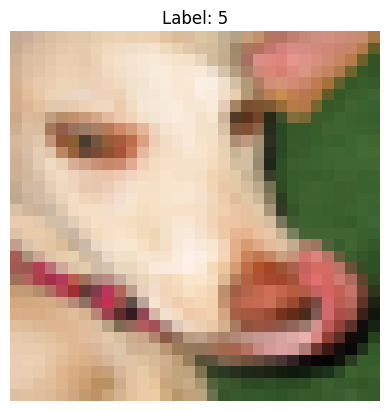

Predicted Label: 0
Actual Label: 2


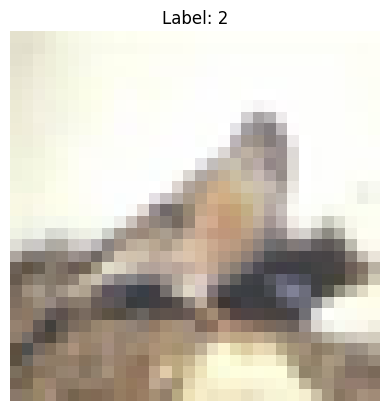

In [ ]:
img_idx = 9
no_of_photos = 2 # least size = 1
sample_img = X_test_scaled[img_idx:img_idx+no_of_photos]
sample_label = y_test[img_idx:img_idx+no_of_photos]

prediction = model.predict(sample_img)
prediction_label = np.argmax(prediction,axis = 1)

for i in range(len(sample_img)):
  print(f'Predicted Label: {prediction_label[i]}')
  print(f'Actual Label: {sample_label[i]}')
  plt.imshow(sample_img[i])
  plt.title(f'Label: {sample_label[i]}')
  plt.axis('off')
  plt.show();

## Stage 2: Custom Convolutional Neural Network (CNN)
To preserve spatial hierarchies, we introduce translation invariance via weight sharing and local receptive fields using convolutional and pooling blocks.
* **Architecture:** 3 Convolutional blocks $(32 \rightarrow 64 \rightarrow 128 \text{ filters})$ followed by spatial MaxPooling and localized Dropout (0.25).
* **Observation:** Significant gain over the flat MLP baseline (~65% accuracy), but performance plateaus due to the model's shallow capacity compared to the visual complexity of natural classes.

### Building a CNN

In [ ]:
cmodel = keras.Sequential([
    layers.Conv2D(filters=32, kernel_size=(3,3), activation='relu', input_shape=Input_shape),
    layers.MaxPooling2D((2,2)),
    layers.Dropout(0.25),
    layers.Conv2D(filters=64, kernel_size=(3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Dropout(0.25),
    layers.Conv2D(filters=128, kernel_size=(3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Dropout(0.25),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.50),
    layers.Dense(class_size, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
cmodel.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

In [ ]:
cmodel.fit(X_train_scaled, y_train, epochs=20, validation_split=0.1, callbacks=[early_stop])

Epoch 1/20
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 14s 6ms/step - accuracy: 0.3011 - loss: 1.8588 - val_accuracy: 0.4640 - val_loss: 1.4862
Epoch 2/20
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.4366 - loss: 1.5484 - val_accuracy: 0.4880 - val_loss: 1.3936
Epoch 3/20
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.4826 - loss: 1.4381 - val_accuracy: 0.5530 - val_loss: 1.2504
Epoch 4/20
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.5147 - loss: 1.3596 - val_accuracy: 0.5838 - val_loss: 1.1962
Epoch 5/20
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.5378 - loss: 1.3034 - val_accuracy: 0.6033 - val_loss: 1.1382
Epoch 6/20
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.5586 - loss: 1.2526 - val_accuracy: 0.5882 - val_loss: 1.1703
Epoch 7/20
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.5755 - loss: 1.2118 - val_accuracy: 0.6388 - val_loss: 1.0351
Epoch 8/20
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.5893 - loss: 1.1701 

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step
Predicted Label: 3
Actual Label: 5


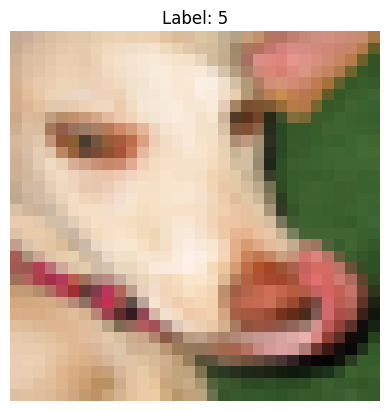

Predicted Label: 0
Actual Label: 2


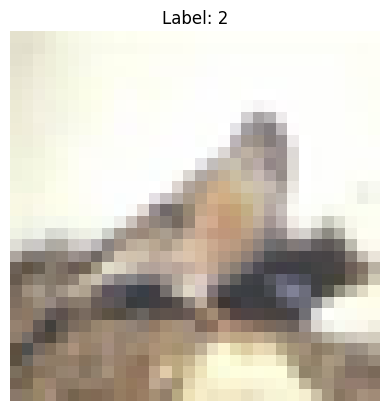

In [ ]:
img_idx = 9
no_of_photos = 2 # least size = 1
sample_img = X_test_scaled[img_idx:img_idx+no_of_photos]
sample_label = y_test[img_idx:img_idx+no_of_photos]

prediction = cmodel.predict(sample_img)
prediction_label = np.argmax(prediction,axis = 1)

for i in range(len(sample_img)):
  print(f'Predicted Label: {prediction_label[i]}')
  print(f'Actual Label: {sample_label[i]}')
  plt.imshow(sample_img[i])
  plt.title(f'Label: {sample_label[i]}')
  plt.axis('off')
  plt.show();

## Stage 3: Transfer Learning via ResNet-50 (Heavy Dense Head)
We leverage inductive transfer by importing a deep ResNet-50 backbone pre-trained on ImageNet.
* **Setup:** Cascaded `UpSampling2D` layers to upscale CIFAR-10 images toward ResNet dimensions, coupled with a deep fully-connected classification head.
* **Trade-off:** High classification accuracy (93.42%), but computationally expensive. Flattening high-dimensional feature maps introduces unnecessary parameters and increases gradient variance.

## Using Transfer Learning with ResNet50

### ResNet50 with dense fully connected layers.

In [8]:
from keras.applications.resnet50 import ResNet50, preprocess_input, decode_predictions
conv_resnet = ResNet50(weights= 'imagenet', include_top= False, input_shape=(256, 256, 3))

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


In [ ]:
num_of_classes = 10

RSmodel = keras.Sequential()
RSmodel.add(layers.UpSampling2D((2, 2)))
RSmodel.add(layers.UpSampling2D((2, 2)))
RSmodel.add(layers.UpSampling2D((2, 2)))
RSmodel.add(conv_resnet)
RSmodel.add(layers.Flatten())
RSmodel.add(layers.BatchNormalization())
RSmodel.add(layers.Dense(128, activation='relu'))
RSmodel.add(layers.Dropout(0.5))
RSmodel.add(layers.BatchNormalization())
RSmodel.add(layers.Dense(64, activation='relu'))
RSmodel.add(layers.Dropout(0.5))
RSmodel.add(layers.BatchNormalization())
RSmodel.add(layers.Dense(num_of_classes, activation='softmax'))

In [ ]:
RSmodel.compile(optimizer=keras.optimizers.RMSprop(learning_rate= 2e-5), loss = 'sparse_categorical_crossentropy', metrics = ['acc'])

In [ ]:
history = RSmodel.fit(X_train_scaled, y_train, validation_split = 0.1, epochs = 10)

Epoch 1/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 461s 362ms/step - acc: 0.4301 - loss: 1.7428 - val_acc: 0.7140 - val_loss: 1.0358
Epoch 2/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 402s 357ms/step - acc: 0.6771 - loss: 1.0773 - val_acc: 0.8740 - val_loss: 0.5444
Epoch 3/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 402s 358ms/step - acc: 0.7896 - loss: 0.7842 - val_acc: 0.9093 - val_loss: 0.4017
Epoch 4/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 402s 357ms/step - acc: 0.8523 - loss: 0.6075 - val_acc: 0.9222 - val_loss: 0.3132
Epoch 5/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 402s 357ms/step - acc: 0.8968 - loss: 0.4786 - val_acc: 0.9295 - val_loss: 0.2763
Epoch 6/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 402s 357ms/step - acc: 0.9246 - loss: 0.3792 - val_acc: 0.9327 - val_loss: 0.2726
Epoch 7/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 402s 357ms/step - acc: 0.9469 - loss: 0.3005 - val_acc: 0.9330 - val_loss: 0.2455
Epoch 8/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 402s 357ms/step - acc: 0.9587 - loss: 0.2501 - val_acc: 0.9337 - val_loss: 0.2381
Epoch 9/

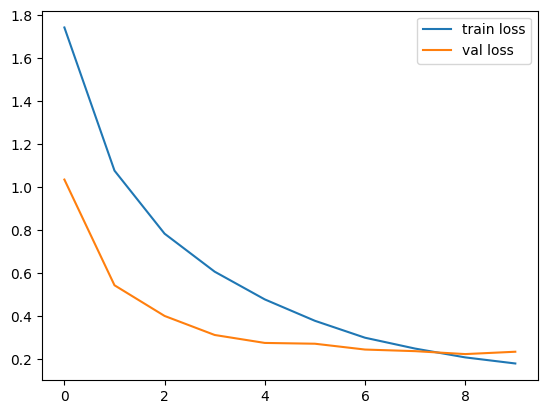

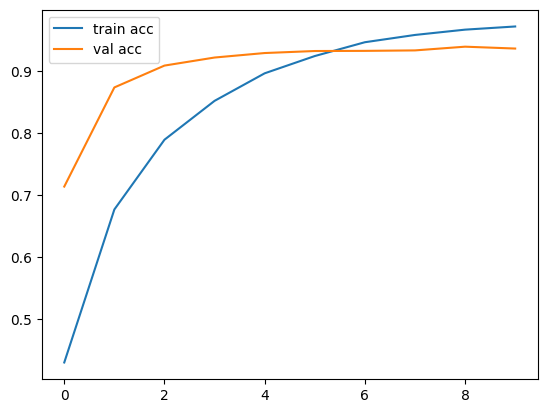

In [ ]:
h = history

#plot loss value
plt.plot(h.history["loss"], label = 'train loss')
plt.plot(h.history["val_loss"], label = 'val loss')
plt.legend()
plt.show()

#plot acc value
plt.plot(h.history["acc"], label = 'train acc')
plt.plot(h.history["val_acc"], label = 'val acc')
plt.legend()
plt.show();

In [ ]:
loss, accuracy = RSmodel.evaluate(X_test_scaled, y_test)
print(accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 42s 118ms/step - acc: 0.9342 - loss: 0.2409
0.9341999888420105


## Stage 4: Optimized Transfer Learning (The Hero Architecture)
To eliminate parameter redundancy and resolve pixel memorization, we redesign the pipeline from first principles:

1. **Dimensional Alignment (224x224):** Scaling the images directly to $224 \times 224$ restores ResNet's native receptive field geometry, preserving high-level feature extractors.
2. **Global Average Pooling (GAP):** Replacing `Flatten` with `GlobalAveragePooling2D` reduces millions of trainable weights into a concise 2048-dimensional vector, acting as a structural regularizer against overfitting.
3. **Data Augmentation:** Injecting `RandomFlip` and `RandomTranslation` forces convolutional filters to generalize semantic boundaries rather than memorizing fixed pixel locations.
4. **Two-Stage Fine-Tuning Strategy:**
   * **Phase 1 (Warm-up):** Freeze the convolutional base (`trainable=False`) and train only the head with $\text{LR} = 10^{-3}$ to stabilize gradients and prevent catastrophic destruction of pre-trained weights.
   * **Phase 2 (Selective Unfreezing):** Unfreeze the top 35 layers and fine-tune with a conservative learning rate ($\text{LR} = 10^{-5}$) using `EarlyStopping` monitoring `val_loss`.

### ResNet with GlobalAveragePooling2D

In [18]:
keras.backend.clear_session()
resnet_conv = ResNet50(weights= 'imagenet', include_top= False, input_shape=(224, 224, 3))
resnet_conv.trainable = False

In [19]:
RSmodel = keras.Sequential()
RSmodel.add(layers.Resizing(224, 224, input_shape = (32,32,3)))
RSmodel.add(layers.RandomFlip("horizontal"))
RSmodel.add(layers.RandomTranslation(0.1, 0.1))
RSmodel.add(layers.Lambda(preprocess_input))
RSmodel.add(resnet_conv)
RSmodel.add(layers.GlobalAveragePooling2D())
RSmodel.add(layers.Dropout(0.5))
RSmodel.add(layers.Dense(10, activation = 'softmax'))

In [20]:
RSmodel.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['acc']
)

In [21]:
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

In [ ]:
Resnetmodel = RSmodel.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=10,
    batch_size=64,
    callbacks=[early_stop]
)

In [ ]:
resnet_conv.trainable = True
for layer in resnet_conv.layers[:140]:
    layer.trainable = False

RSmodel.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['acc']
)

resnetmodel_finetune = RSmodel.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=20,
    batch_size=64,
    callbacks=[early_stop]
)

In [15]:
test_loss, test_acc = RSmodel.evaluate(X_test, y_test)
print(f"Final Test Accuracy: {test_acc * 100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 44s 140ms/step - acc: 0.9423 - loss: 0.1814
Final Test Accuracy: 94.23%


In [16]:
RSmodel.save('cifar10_resnet50_clean_finetuned.keras')

## Key Engineering Takeaways
1. **Catastrophic Forgetting Mitigation:** Unfreezing deep backbones immediately destroys pre-trained feature detectors. A two-stage warm-up is essential to stabilize head representations.
2. **Combating Overfitting:** Heavy fully-connected layers memorize training data quickly (reaching 99% train accuracy prematurely). Spatial augmentation combined with Global Average Pooling provides structural regularization that generalizes cleanly to unseen test sets.
3. **Resolution Sensitivity:** ResNet architectures are sensitive to spatial input degradation. Upscaling CIFAR-10 to native resolution ($224 \times 224$) extracts maximum utility from pre-trained ImageNet priors, pushing model accuracy to **94.23%**.